In [1]:
from neo4j import GraphDatabase, RoutingControl

# Informasi koneksi database
URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "GSD12345")

# Membuat node Person dan relationship KNOWS
def add_friend(driver, name, friend_name):
    driver.execute_query(
        """
        MERGE (a:Person {name: $name})
        MERGE (friend:Person {name: $friend_name})
        MERGE (a)-[:KNOWS]->(friend)
        """,
        name=name,
        friend_name=friend_name,
        database_="UTS",
    )

# Menampilkan teman dari seseorang
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        """
        MATCH (a:Person)-[:KNOWS]->(friend)
        WHERE a.name = $name
        RETURN friend.name AS friend_name
        ORDER BY friend_name
        """,
        name=name,
        database_="UTS",
        routing_=RoutingControl.READ,
    )

    for record in records:
        print(record["friend_name"])


# Menjalankan tutorial
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()

    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")

    print("Teman Arthur:")
    print_friends(driver, "Arthur")

Teman Arthur:
Guinevere
Lancelot
Merlin


# Pertanyaan Pendahuluan (Checkpoint)

1. Apa nama database yang digunakan pada tutorial ini?
   ```
   database_ = "uts"
   ```
2. Sebutkan akses lain (seperti sintaks DDL/DML Cypher) yang dapat digunakan untuk mengakses database lain dalam satu instance!
   ```cypher
   SHOW DATABASES;

   USE nama_database;
   MATCH (n)
   RETURN n;

   CREATE DATABASE database_baru;
3. Apa jenis graf pertemanan yang telah dibuat di sini?

   Graf Berarah (Directed Graph / Digraph)

In [2]:
import os
import pandas as pd

folder = r"C:\Users\acer\Documents\latihan\graf\UTS"

# Periksa semua file dalam folder
print(os.listdir(folder))

['category_tree.csv', 'Dataset.zip', 'events.csv', 'events_P1_training.csv', 'events_P2_testing.csv', 'item_ids_P1.npy', 'item_properties_part1.csv', 'item_properties_part2.csv', 'R_P1_user_item.npz', 'similarity_item_topK_P1.csv', 'user_ids_P1.npy']


In [3]:
events_path = os.path.join(folder, "events.csv")

df = pd.read_csv(events_path)

print("Ukuran dataset:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

print("\nLima baris pertama:")
display(df.head())

print("\nInformasi dataset:")
df.info()

Ukuran dataset: (2756101, 5)

Nama kolom:
['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']

Lima baris pertama:


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN



Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          object 
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), object(1)
memory usage: 105.1+ MB


In [6]:
from neo4j import GraphDatabase

URI = "neo4j://localhost:7687"
USER = "neo4j"
PASSWORD = "GSD12345"

driver = GraphDatabase.driver(
    URI,
    auth=(USER, PASSWORD)
)

driver.verify_connectivity()

print("Koneksi Neo4j berhasil!")

Koneksi Neo4j berhasil!


In [7]:
import argparse
import os
import sys

import pandas as pd
from tqdm.auto import tqdm
from neo4j import GraphDatabase


# Konfigurasi koneksi Neo4j
URI = "neo4j://127.0.0.1:7687"
USER = "neo4j"
PASSWORD = "GSD12345"

SOURCE = r"C:\Users\acer\Documents\latihan\graf\UTS"


def parse_arguments(args=None):
    parser = argparse.ArgumentParser(
        description="Impor dataset RetailRocket (events.csv) ke database UTS."
    )

    parser.add_argument(
        "-u", "--user",
        default=USER,
        help="Username Neo4j"
    )

    parser.add_argument(
        "-p", "--password",
        default=PASSWORD,
        help="Password Neo4j"
    )

    parser.add_argument(
        "-b", "--bolt",
        default=URI,
        help="URI koneksi Neo4j"
    )

    parser.add_argument(
        "-s", "--source",
        default=SOURCE,
        help="Folder sumber data"
    )

    # args=None untuk terminal; args=[] untuk Jupyter
    return parser.parse_args(args=args)


def main():
    args = parse_arguments(args=[])

    csv_file_path = os.path.join(
        args.source,
        "events.csv"
    )

    # Periksa keberadaan file
    if not os.path.exists(csv_file_path):
        print(f"Error: File '{csv_file_path}' tidak ditemukan!")
        sys.exit(1)

    print(f"File dataset ditemukan: {csv_file_path}")

    # Periksa koneksi Neo4j
    driver = None

    try:
        driver = GraphDatabase.driver(
            args.bolt,
            auth=(args.user, args.password)
        )

        driver.verify_connectivity()
        print("Koneksi Neo4j berhasil!")

    except Exception as e:
        print(f"Gagal terhubung ke database: {e}")
        sys.exit(1)

    finally:
        if driver is not None:
            driver.close()


if __name__ == "__main__":
    main()

File dataset ditemukan: C:\Users\acer\Documents\latihan\graf\UTS\events.csv
Koneksi Neo4j berhasil!


c:\Users\acer\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [8]:
def create_constraints(session):
    session.run("""
        CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorId IS UNIQUE
    """)

    session.run("""
        CREATE CONSTRAINT item_id_unique IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.itemId IS UNIQUE
    """)

    print("Constraint Visitor dan Item berhasil dibuat.")

In [9]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row

    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row

    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionId: row.transactionid
        }]->(i)
    }
    """

    tx.run(cypher_query, batch=batch)

In [10]:
with GraphDatabase.driver(
    URI,
    auth=(USER, PASSWORD)
) as driver:
    with driver.session(database="UTS") as session:
        create_constraints(session)

Constraint Visitor dan Item berhasil dibuat.


In [19]:

import os
import pandas as pd
from tqdm.auto import tqdm
from neo4j import GraphDatabase

# Lokasi dataset
csv_file_path = os.path.join(SOURCE, "events.csv")

# Ukuran setiap batch
batch_size = 10_000

# Pastikan file tersedia
if not os.path.exists(csv_file_path):
    raise FileNotFoundError(f"File tidak ditemukan: {csv_file_path}")

# Hitung jumlah baris CSV
with open(csv_file_path, "r", encoding="utf-8") as f:
    total_rows = sum(1 for _ in f) - 1

total_chunks = (total_rows + batch_size - 1) // batch_size

print("File:", csv_file_path)
print("Total baris:", total_rows)
print("Total batch:", total_chunks)

# Proses impor
with GraphDatabase.driver(
    URI,
    auth=(USER, PASSWORD)
) as driver:

    driver.verify_connectivity()

    with driver.session(database="UTS") as session:

        # Pastikan constraint tersedia
        create_constraints(session)

        chunks = pd.read_csv(
            csv_file_path,
            chunksize=batch_size
        )

        # Gunakan pola progress bar dari kode P1
        run_write = getattr(session, "execute_write", None) or session.write_transaction

        for chunk in tqdm(
            chunks,
            total=total_chunks,
            desc="Mengimpor data"
        ):
            # Bersihkan transactionid kosong
            chunk["transactionid"] = (
                chunk["transactionid"]
                .fillna("")
                .astype(str)
            )

            # Ubah batch menjadi list dictionary
            records = chunk.to_dict(orient="records")

            # Kirim batch ke Neo4j
            run_write(import_batch, records)

print("Proses impor selesai!")


File: C:\Users\acer\Documents\latihan\graf\UTS\events.csv
Total baris: 2756101
Total batch: 276
Constraint Visitor dan Item berhasil dibuat.


Exception ignored in: <function tqdm.__del__ at 0x000001EFDD6827A0>
Traceback (most recent call last):
  File "c:\Users\acer\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\std.py", line 1148, in __del__
    self.close()
  File "c:\Users\acer\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\notebook.py", line 277, in close
    self.disp(bar_style='danger', check_delay=False)
    ^^^^^^^^^
AttributeError: 'tqdm_notebook' object has no attribute 'disp'
Mengimpor data: 100%|██████████| 276/276 [04:47<00:00,  1.04s/it]

Proses impor selesai!


# 2.1 Wrangling dan EDA
## 1
| Periode | Rentang Waktu               | Penggunaan    |
| ------- | --------------------------- | ------------- |
| P1      | 1 Juni – 30 Juni 2015       | Data training |
| P2      | 1 Agustus – 31 Agustus 2015 | Data testing  |

In [11]:
import pandas as pd
import os
import numpy as np
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
from neo4j import GraphDatabase
from tqdm import tqdm
import time
import math

## 2

In [12]:
SOURCE = r"C:\Users\acer\Documents\latihan\graf\UTS"

events = pd.read_csv(os.path.join(SOURCE, "events.csv"))

# Konversi Unix timestamp milidetik ke datetime
events["datetime"] = pd.to_datetime(
    events["timestamp"],
    unit="ms",
    utc=True
)

# Periode training: Juni 2015
p1 = events[
    (events["datetime"] >= "2015-06-01") &
    (events["datetime"] < "2015-07-01")
].copy()

# Periode testing: Agustus 2015
p2 = events[
    (events["datetime"] >= "2015-08-01") &
    (events["datetime"] < "2015-09-01")
].copy()

# Simpan masing-masing periode
p1.to_csv(
    os.path.join(SOURCE, "events_P1_training.csv"),
    index=False
)

p2.to_csv(
    os.path.join(SOURCE, "events_P2_testing.csv"),
    index=False
)

print("Jumlah data P1:", len(p1))
print("Jumlah data P2:", len(p2))
print("File CSV berhasil disimpan.")

Jumlah data P1: 610393
Jumlah data P2: 553362
File CSV berhasil disimpan.


## 3

In [13]:
SOURCE = r"C:\Users\acer\Documents\latihan\graf\UTS"
CSV_P1 = os.path.join(SOURCE, "events_P1_training.csv")

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "GSD12345")      
DATABASE = "UTS"
BATCH_SIZE = 2_000                

if not os.path.exists(CSV_P1):
    raise FileNotFoundError(f"File tidak ditemukan: {CSV_P1}")

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("Terhubung ke Neo4j.")

#Reset database guna menghindari eror memori
def reset_db(driver, batch=5_000):
    total = 0
    while True:
        with driver.session(database=DATABASE) as session:
            deleted = session.run(
                """
                MATCH (n) WITH n LIMIT $batch
                DETACH DELETE n
                RETURN count(*) AS c
                """,
                batch=batch,
            ).single()["c"]
        total += deleted
        if deleted == 0:
            break
    print(f"Reset selesai. Simpul terhapus: {total}")

reset_db(driver)  

#Constraint
def create_constraints(session):
    session.run("""CREATE CONSTRAINT visitor_id IF NOT EXISTS
                   FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE""")
    session.run("""CREATE CONSTRAINT item_id IF NOT EXISTS
                   FOR (i:Item) REQUIRE i.itemId IS UNIQUE""")

with driver.session(database=DATABASE) as session:
    create_constraints(session)
print("Constraint dibuat.")

#Query impor per jenis event
Q_VIEW = """
UNWIND $batch AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
"""
Q_CART = """
UNWIND $batch AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
"""
Q_BUY = """
UNWIND $batch AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
"""
QUERIES = {"view": Q_VIEW, "addtocart": Q_CART, "transaction": Q_BUY}


def import_batch(tx, query, batch):
    tx.run(query, batch=batch)


#Impor P1
def clean_txid(x):
    return "" if pd.isna(x) else str(int(x))

total_rows = sum(1 for _ in open(CSV_P1, encoding="utf-8")) - 1
total_chunks = total_rows // BATCH_SIZE + 1
print("Total baris P1:", total_rows)

with driver.session(database=DATABASE) as session:
    run_write = getattr(session, "execute_write", None) or session.write_transaction
    for chunk in tqdm(pd.read_csv(CSV_P1, chunksize=BATCH_SIZE),
                      total=total_chunks, desc="Impor P1"):
        chunk["transactionid"] = chunk["transactionid"].apply(clean_txid)
        chunk = chunk[["timestamp", "visitorid", "event", "itemid", "transactionid"]]
        for event, query in QUERIES.items():
            rows = chunk[chunk["event"] == event].to_dict(orient="records")
            if rows:
                run_write(import_batch, query, rows)
print("Impor selesai.")

#Query komposisi subgraph
def run_query(query):
    with driver.session(database=DATABASE) as session:
        return [r.data() for r in session.run(query)]

q_nodes = """
MATCH (n)
RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah
ORDER BY jumlah DESC
"""
q_rels = """
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(r) AS jumlah
ORDER BY jumlah DESC
"""
q_pattern = """
MATCH (a)-[r]->(b)
RETURN labels(a)[0] AS dari, type(r) AS relasi, labels(b)[0] AS ke, count(*) AS jumlah
ORDER BY jumlah DESC
"""

df_nodes = pd.DataFrame(run_query(q_nodes))
df_rels = pd.DataFrame(run_query(q_rels))
df_pattern = pd.DataFrame(run_query(q_pattern))

print("== Jumlah simpul per jenis ==");  print(df_nodes, "\n")
print("== Jumlah relasi per jenis ==");  print(df_rels, "\n")
print("== Pola graf ==");                print(df_pattern)
print("\nTotal relasi:", df_rels["jumlah"].sum(), "(harus sama dengan", total_rows, ")")

p1 = pd.read_csv(CSV_P1)
validasi = pd.DataFrame({
    "Neo4j": [
        int(df_nodes.loc[df_nodes.jenis_simpul == "Visitor", "jumlah"].sum()),
        int(df_nodes.loc[df_nodes.jenis_simpul == "Item", "jumlah"].sum()),
    ],
    "pandas": [p1["visitorid"].nunique(), p1["itemid"].nunique()],
}, index=["Visitor", "Item"])
print(validasi)
print(p1["event"].value_counts())

Terhubung ke Neo4j.
Reset selesai. Simpul terhapus: 4
Constraint dibuat.
Total baris P1: 610393


Impor P1: 100%|██████████| 306/306 [01:09<00:00,  4.42it/s]


Impor selesai.
== Jumlah simpul per jenis ==
  jenis_simpul  jumlah
0      Visitor  313832
1         Item  117317 

== Jumlah relasi per jenis ==
    jenis_relasi  jumlah
0         VIEWED  590255
1  ADDED_TO_CART   15095
2         BOUGHT    5043 

== Pola graf ==
      dari         relasi    ke  jumlah
0  Visitor         VIEWED  Item  590255
1  Visitor  ADDED_TO_CART  Item   15095
2  Visitor         BOUGHT  Item    5043

Total relasi: 610393 (harus sama dengan 610393 )
          Neo4j  pandas
Visitor  313832  313832
Item     117317  117317
event
view           590255
addtocart       15095
transaction      5043
Name: count, dtype: int64


## Penjelasan Sintaks Cypher

1. Menghitung jumlah simpul berdasarkan label
   ```
   MATCH (n)
   RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah;
   ```
   `MATCH (n)` mencocokkan semua simpul tanpa memandang label. `labels(n)` mengembalikan daftar label, sedangkan `[0]` mengambil label pertama. `count(n)` menghitung jumlah simpul. Karena label ikut ditampilkan bersama fungsi agregasi, Cypher mengelompokkan hasil berdasarkan label, mirip `GROUP BY` di SQL.
2. Menghitung jumlah relasi berdasarkan tipe
   ```
   MATCH ()-[r]->()
   RETURN type(r), count(r);
   ```
   Pola ini mencocokkan semua relasi berarah. `type(r)` mengembalikan nama tipe relasi, sedangkan `count(r)` menghitung jumlah relasi untuk setiap tipe.
3. Menampilkan skema graf
   ```
   MATCH (a)-[r]->(b)
   RETURN labels(a)[0], type(r), labels(b)[0], count(*);
   ```
   Pola ini menggabungkan label simpul asal, tipe relasi, dan label simpul tujuan. Hasilnya menunjukkan struktur atau skema graf, misalnya:

   `Visitor -[VIEWED | ADDED_TO_CART | BOUGHT]-> Item`
4. Mengurutkan hasil berdasarkan jumlah
   ```
   ORDER BY jumlah DESC
   ```
   `ORDER BY` mengurutkan hasil, sedangkan `DESC` menentukan urutan menurun, dari jumlah terbesar ke terkecil.

## 1. Validasi: Impor Berjalan dengan Benar

- Total relasi sebanyak 610.393 sama dengan jumlah baris P1. Setiap baris CSV berhasil diimpor menjadi satu relasi tanpa ada data yang hilang atau terduplikasi.
- Seluruh angka di Neo4j sesuai dengan hasil perhitungan pandas, baik untuk simpul `Visitor`, `Item`, maupun ketiga jenis relasi interaksi. Hal ini menjadi bukti bahwa proses impor data berjalan dengan benar.
- Proses reset hanya menyisakan empat simpul, berbeda dari kondisi sebelumnya yang memiliki sekitar 1,68 juta simpul. Keempat simpul tersebut kemungkinan merupakan sisa tutorial 1.2, yaitu Arthur, Guinevere, Lancelot, dan Merlin. Dengan demikian, graf saat ini hampir seluruhnya berisi data P1.

## 2. Komposisi Graf

| Ukuran                 | Nilai     |
| ---------------------- | --------- |
| Total simpul           | 431.149   |
| Proporsi `Visitor`     | 72,8%     |
| Proporsi `Item`        | 27,2%     |
| Rasio `Visitor : Item` | ≈ 2,7 : 1 |
| Interaksi per visitor  | ≈ 1,95    |
| Interaksi per item     | ≈ 5,20    |

Jumlah simpul `Visitor` hampir tiga kali lebih banyak daripada simpul `Item`. Namun, setiap visitor hanya melakukan rata-rata sekitar dua interaksi. Hal ini memberikan indikasi awal bahwa graf memiliki tingkat keterhubungan yang rendah atau bersifat sparse. Kondisi tersebut nantinya dikonfirmasi pada Soal 4 dengan nilai sparsity sebesar 99,9987%.

## 3. Komposisi Relasi (Funnel Perilaku)

| Jenis Relasi    | Jumlah  | Proporsi | Rasio Kasar                                     |
| --------------- | ------- | -------- | ----------------------------------------------- |
| `VIEWED`        | 590.255 | 96,70%   | —                                               |
| `ADDED_TO_CART` | 15.095  | 2,47%    | 2,56% dari `VIEWED`                             |
| `BOUGHT`        | 5.043   | 0,83%    | 33,4% dari `ADDED_TO_CART`; 0,85% dari `VIEWED` |

Komposisi relasi menunjukkan pola seperti corong perilaku e-commerce (e-commerce funnel). Sebagian besar interaksi berupa aktivitas melihat produk, sedangkan aktivitas menambahkan produk ke keranjang dan membeli produk jumlahnya jauh lebih sedikit.

Secara kasar, jumlah relasi `BOUGHT` setara dengan 33,4% jumlah relasi `ADDED_TO_CART`. Namun, rasio tersebut tidak dapat langsung dianggap sebagai tingkat konversi pembelian yang sebenarnya karena tidak ada jaminan bahwa aktivitas pembelian berasal dari aktivitas keranjang yang sama atau terjadi dalam periode yang sama.

## 4. Multigraph: Banyak Interaksi Berulang

Terdapat 610.393 relasi, sedangkan jumlah pasangan `Visitor–Item` yang unik hanya 471.258 berdasarkan hasil Soal 4.

Dengan demikian, terdapat selisih:

\\[ 610.393-471.258=139.135 \\]

Selisih tersebut setara dengan sekitar 22,8% dari total relasi. Hal ini menunjukkan adanya relasi tambahan pada pasangan visitor dan item yang sama, misalnya visitor melihat item yang sama berulang kali atau melakukan beberapa jenis interaksi terhadap item tersebut.

Struktur ini dapat diperlakukan sebagai multigraph karena satu pasangan simpul dapat memiliki beberapa relasi yang merepresentasikan interaksi berbeda. Dalam membangun matriks interaksi \\(R\\), bobot dari interaksi pada pasangan `Visitor–Item` yang sama dapat dijumlahkan sesuai metode yang digunakan.

## 5. Struktur Graf

Graf memiliki pola hubungan utama sebagai berikut:

## Visitor

Simpul pengguna

## Item

Simpul produk

Relasi: VIEWED, ADDED_TO_CART, BOUGHT

Graf tersebut termasuk graf bipartit berarah (directed bipartite graph) karena memiliki dua kelompok simpul, yaitu `Visitor` dan `Item`, dengan arah relasi dari visitor menuju item. Tidak terdapat relasi langsung antarsimpul `Visitor` maupun antarsimpul `Item` pada struktur interaksi awal.

Oleh karena itu, untuk menghitung kemiripan antaritem atau antarvisitor, diperlukan proses proyeksi graf. Proses tersebut menjadi dasar analisis pada Soal 6 dan Soal 7.

## 4 DAN 5


Pasangan user-item unik: 471258
Vektor                  User (baris R) Item (baris R^T)
Shape                  313832 x 117317  117317 x 313832
Dimensi vektor                  117317           313832
Jumlah vektor                   313832           117317
Non-zero (nnz)                  471258           471258
Density (%)                    0.00128          0.00128
Sparsity (%)                  99.99872         99.99872
Memori dense (GB)            294.54263        294.54263
Memori sparse (MB)            6.910428         6.124368
Rata2 nnz/vektor              1.501625         4.016963
Median nnz/vektor                  1.0              2.0
Maks nnz/vektor                   1031             1022
Vektor dg 1 nnz (%)          80.370389        48.428616
Vektor dg >=3 nnz (%)         7.907097        34.250791


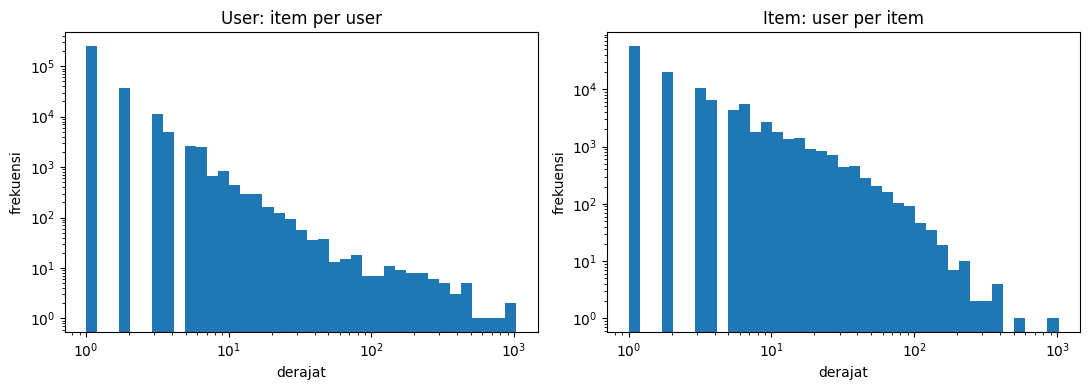

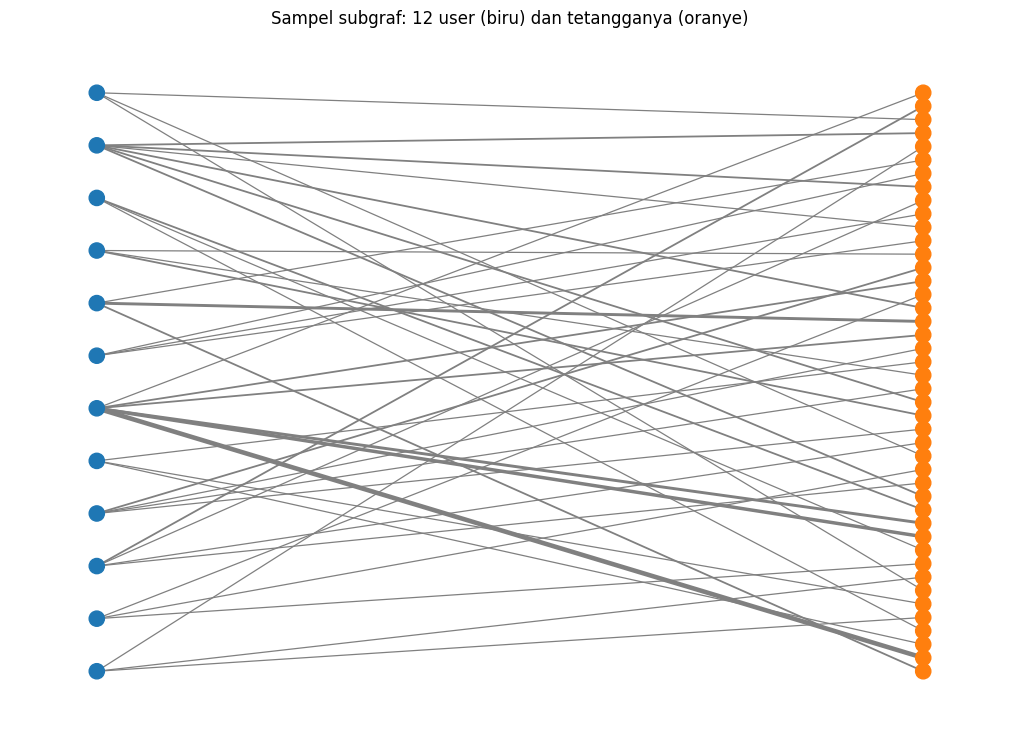

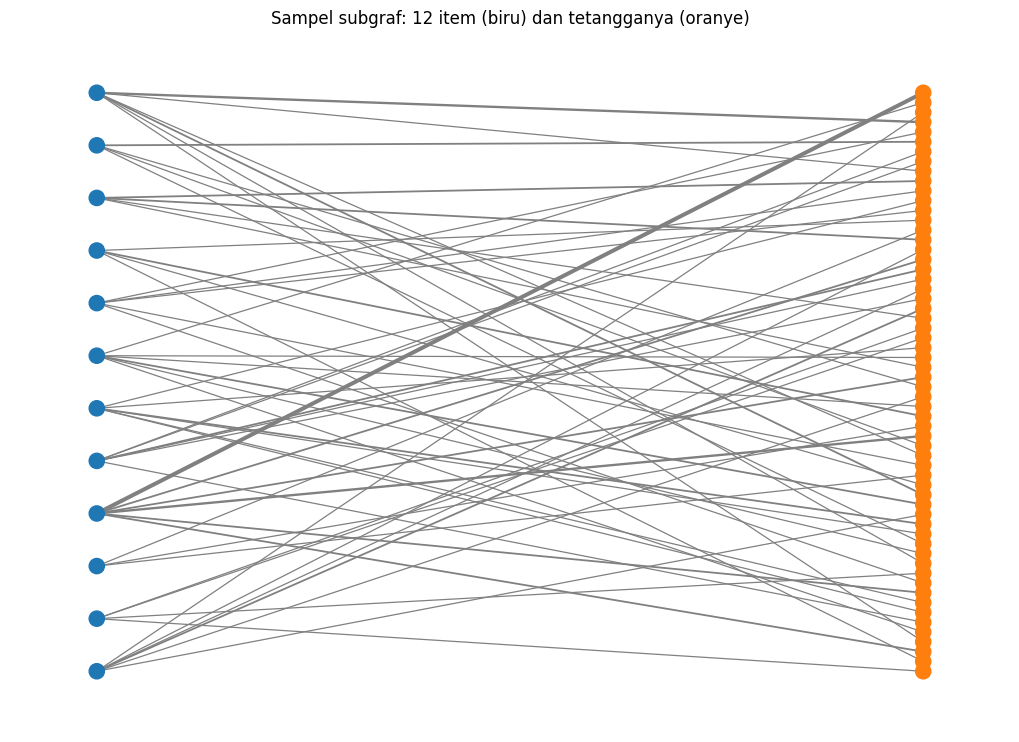

Batas atas edge proyeksi User-User: 5,842,801
Batas atas edge proyeksi Item-Item: 4,068,966


In [14]:
SOURCE = r"C:\Users\acer\Documents\latihan\graf\UTS"
URI, AUTH, DATABASE = "neo4j://127.0.0.1:7687", ("neo4j", "GSD12345"), "UTS"

try:
    driver.verify_connectivity()
except Exception:
    driver = GraphDatabase.driver(URI, auth=AUTH)
    driver.verify_connectivity()

def run_query(query, **params):
    with driver.session(database=DATABASE) as session:
        return [r.data() for r in session.run(query, **params)]

# Bobot (implicit feedback): VIEWED=1, ADDED_TO_CART=3, BOUGHT=5
q_edges = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS u, i.itemId AS i,
       sum(CASE type(r)
             WHEN 'VIEWED' THEN 1
             WHEN 'ADDED_TO_CART' THEN 3
             WHEN 'BOUGHT' THEN 5
           END) AS w
"""
df = pd.DataFrame(run_query(q_edges))
print("Pasangan user-item unik:", len(df))

#matriks sparse R (user x item)
user_ids = np.sort(df["u"].unique())
item_ids = np.sort(df["i"].unique())
u_idx = pd.Index(user_ids).get_indexer(df["u"])
i_idx = pd.Index(item_ids).get_indexer(df["i"])

R = sp.csr_matrix((df["w"].astype(float), (u_idx, i_idx)),
                  shape=(len(user_ids), len(item_ids)))
Rt = R.T.tocsr()                      # VSM Item: (item x user)

sp.save_npz(os.path.join(SOURCE, "R_P1_user_item.npz"), R)
np.save(os.path.join(SOURCE, "user_ids_P1.npy"), user_ids)
np.save(os.path.join(SOURCE, "item_ids_P1.npy"), item_ids)

#Karakteristik VSM
def describe(M, nama):
    n, d = M.shape
    nnz = M.nnz
    per_row = np.diff(M.indptr)                   
    info = {
        "Vektor": nama,
        "Shape": f"{n} x {d}",
        "Dimensi vektor": d,
        "Jumlah vektor": n,
        "Non-zero (nnz)": nnz,
        "Density (%)": 100 * nnz / (n * d),
        "Sparsity (%)": 100 * (1 - nnz / (n * d)),
        "Memori dense (GB)": n * d * 8 / 1e9,
        "Memori sparse (MB)": (M.data.nbytes + M.indices.nbytes + M.indptr.nbytes) / 1e6,
        "Rata2 nnz/vektor": per_row.mean(),
        "Median nnz/vektor": np.median(per_row),
        "Maks nnz/vektor": per_row.max(),
        "Vektor dg 1 nnz (%)": 100 * (per_row == 1).mean(),
        "Vektor dg >=3 nnz (%)": 100 * (per_row >= 3).mean(),
    }
    return info

hasil = pd.DataFrame([describe(R, "User (baris R)"),
                      describe(Rt, "Item (baris R^T)")]).set_index("Vektor").T
print(hasil.to_string())

# Distribusi derajat (nnz per vektor), skala log
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, M, t in zip(ax, [R, Rt], ["User: item per user", "Item: user per item"]):
    deg = np.diff(M.indptr)
    a.hist(deg, bins=np.logspace(0, np.log10(deg.max() + 1), 40))
    a.set_xscale("log"); a.set_yscale("log")
    a.set_title(t); a.set_xlabel("derajat"); a.set_ylabel("frekuensi")
plt.tight_layout(); plt.show()

#Plot networkx
rng = np.random.default_rng(42)

def plot_subgraph(center="user", n_center=12, max_nbr=6, seed=42):
    M = R if center == "user" else Rt
    ids_c = user_ids if center == "user" else item_ids
    ids_n = item_ids if center == "user" else user_ids
    deg = np.diff(M.indptr)
    kandidat = np.where(deg >= 3)[0]
    pilih = np.random.default_rng(seed).choice(kandidat, n_center, replace=False)

    G = nx.Graph()
    for r in pilih:
        c_node = f"{'U' if center=='user' else 'I'}{ids_c[r]}"
        G.add_node(c_node, bip=0)
        cols = M.indices[M.indptr[r]:M.indptr[r + 1]]
        w = M.data[M.indptr[r]:M.indptr[r + 1]]
        top = np.argsort(-w)[:max_nbr]
        for c, ww in zip(cols[top], w[top]):
            n_node = f"{'I' if center=='user' else 'U'}{ids_n[c]}"
            G.add_node(n_node, bip=1)
            G.add_edge(c_node, n_node, weight=ww)

    top_nodes = [n for n, d in G.nodes(data=True) if d["bip"] == 0]
    pos = nx.bipartite_layout(G, top_nodes)
    warna = ["tab:blue" if G.nodes[n]["bip"] == 0 else "tab:orange" for n in G]
    lebar = [0.5 + 0.4 * G[u][v]["weight"] for u, v in G.edges]
    plt.figure(figsize=(10, 7))
    nx.draw(G, pos, node_color=warna, width=lebar, node_size=120, with_labels=False, edge_color="gray")
    plt.title(f"Sampel subgraf: {n_center} {center} (biru) dan tetangganya (oranye)")
    plt.show()
    return G

G_user = plot_subgraph("user")   # Soal 4: sudut pandang User
G_item = plot_subgraph("item")   # Soal 5: sudut pandang Item

B = R.copy(); B.data[:] = 1
deg_u = np.asarray(B.sum(axis=1)).ravel()     # item per user
deg_i = np.asarray(B.sum(axis=0)).ravel()     # user per item
est_user_user = (deg_i * (deg_i - 1) / 2).sum()   # pasangan user via item bersama (batas atas)
est_item_item = (deg_u * (deg_u - 1) / 2).sum()   # pasangan item via user bersama (batas atas)
print(f"Batas atas edge proyeksi User-User: {est_user_user:,.0f}")
print(f"Batas atas edge proyeksi Item-Item: {est_item_item:,.0f}")

## Insight Soal 4 (VSM User)
- Vektor user sangat pendek isinya. Median hanya 1 item, dan 80,4% user berinteraksi dengan satu item saja. Vektor satu elemen hanya bisa dibandingkan lewat satu “koordinat”, jadi similarity user-user akan kasar dan sering ekstrem (0 atau 1).
- Hanya sekitar 7,9% user yang punya riwayat cukup (≥3 item) untuk rekomendasi berbasis riwayat. Selebihnya mengalami cold-start.
- Distribusi heavy-tailed: median 1 tetapi maksimum 1.031. Segelintir user sangat aktif, kemungkinan bot atau crawler, dan satu user seperti itu menyumbang sekitar 531 ribu pasangan di proyeksi.
- Rata-rata unik 1,50 item per user lebih kecil daripada 1,95 interaksi per visitor (Soal 3). Selisihnya berasal dari interaksi berulang pada item yang sama.

## Insight Soal 5 (VSM Item)
- Vektor item lebih kaya. Median 2 user, rata-rata 4,02, dan 34,3% item punya ≥3 user. Hanya 48,4% item yang hanya punya satu user.
- Tetap heavy-tailed: satu item dilihat 1.022 user. Item populer seperti ini cenderung mendominasi similarity, jadi layak disebut sebagai bias popularitas.
- Hampir separuh item (≈ 56,8 ribu) hanya punya satu user, sehingga tidak bisa dihitung kemiripannya secara andal. Ini menjelaskan mengapa hanya 15,3% item akhirnya punya tetangga di Soal 7.

## 6
Berdasarkan eksplorasi VSM, proyeksi Item-Item dipilih. Dengan nnz yang sama (471.258), vektor item lebih informatif: hanya 48,4% item yang memiliki satu pengguna, dibandingkan 80,4% user yang hanya memiliki satu item. Jumlah simpul proyeksi lebih sedikit (117.317 vs 313.832) dan batas atas edge lebih kecil (4,07 juta vs 5,84 juta), sehingga komputasi dan memori lebih efisien. Selain itu, katalog item lebih stabil antar periode (P1 → P2) dibandingkan populasi pengunjung, serta mendukung user baru melalui riwayat item-nya. Keterbatasan: distribusi derajat bersifat heavy-tailed sehingga sejumlah kecil hub berkontribusi besar terhadap jumlah pasangan.

## 7

Selesai 0.7 dtk | pasangan (arah) tersisa: 342,600
Item punya tetangga : 17927
Relasi SIMILAR_TO   : 85350
count    85350.000000
mean         0.253518
std          0.227753
min          0.001808
25%          0.082234
50%          0.171793
75%          0.363640
max          1.000000
Name: score, dtype: float64
SEBELUM:
          relasi  jumlah
0         VIEWED  590255
1  ADDED_TO_CART   15095
2         BOUGHT    5043


Tulis SIMILAR_TO: 100%|██████████| 43/43 [00:11<00:00,  3.79it/s]


SESUDAH:
          relasi  jumlah
0         VIEWED  590255
1     SIMILAR_TO   85350
2  ADDED_TO_CART   15095
3         BOUGHT    5043
Item acuan: 47448 | jumlah user: 40
 item_acuan  item_mirip  similarity  user_bersama
      47448       87789    0.625997             7
      47448      422481    0.181689             2
      47448        8748    0.096601             5
      47448      341526    0.047746             2
      47448      240470    0.040204             4
 dari     relasi                                             properti     ke
47448 SIMILAR_TO {'score': 0.625997, 'common': 7, 'method': 'cosine'}  87789
47448 SIMILAR_TO {'score': 0.181689, 'common': 2, 'method': 'cosine'} 422481
47448 SIMILAR_TO {'score': 0.096601, 'common': 5, 'method': 'cosine'}   8748
47448 SIMILAR_TO {'score': 0.047746, 'common': 2, 'method': 'cosine'} 341526
47448 SIMILAR_TO {'score': 0.040204, 'common': 4, 'method': 'cosine'} 240470

MATCH p=(a:Item {itemId: 47448})-[s:SIMILAR_TO]->(b:Item)
RETURN p 

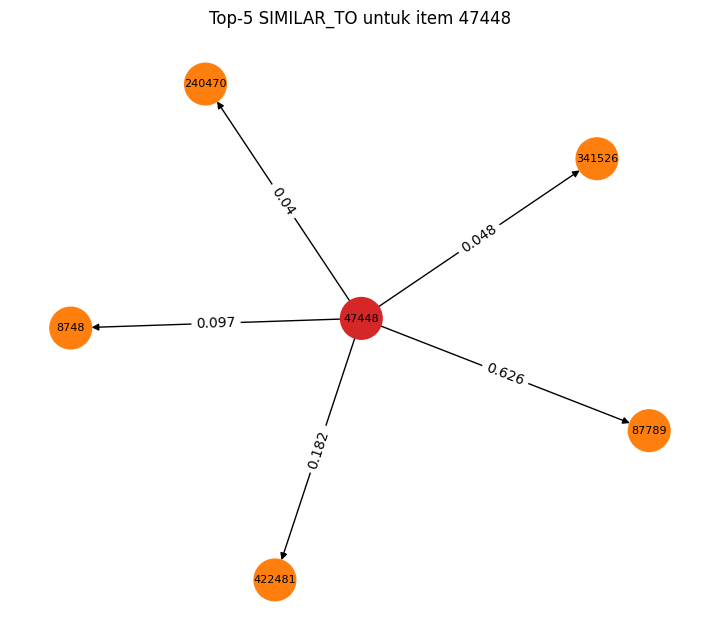

In [15]:
SOURCE = r"C:\Users\acer\Documents\latihan\graf\UTS"
URI, AUTH, DATABASE = "neo4j://127.0.0.1:7687", ("neo4j", "GSD12345"), "UTS"

try:
    driver.verify_connectivity()
except Exception:
    driver = GraphDatabase.driver(URI, auth=AUTH)
    driver.verify_connectivity()

def run_query(query, **params):
    with driver.session(database=DATABASE) as session:
        return [r.data() for r in session.run(query, **params)]

try:
    R, Rt, item_ids
except NameError:  
    R = sp.load_npz(os.path.join(SOURCE, "R_P1_user_item.npz")).tocsr()
    Rt = R.T.tocsr()
    item_ids = np.load(os.path.join(SOURCE, "item_ids_P1.npy"))

#Parameter
K = 10            # tetangga terdekat yang disimpan per item
MIN_COMMON = 2    # minimal jumlah user bersama (mencegah similarity 1.0 palsu dari 1 user)
SEED = 42

#Cosine similarity item-item 
t0 = time.time()
norms = np.sqrt(np.asarray(Rt.multiply(Rt).sum(axis=1)).ravel())
Rn = sp.diags(1.0 / norms) @ Rt                  # tiap baris (item) berpanjang 1
S = (Rn @ Rn.T).tocsr()                          # cosine = dot product vektor ternormalisasi

# jumlah user bersama (matriks biner)
Bt = Rt.copy(); Bt.data[:] = 1
C = (Bt @ Bt.T).tocsr()

S.setdiag(0)
mask = C.copy(); mask.data = (mask.data >= MIN_COMMON).astype(float); mask.eliminate_zeros()
S = S.multiply(mask).tocsr(); S.eliminate_zeros()
print(f"Selesai {time.time()-t0:.1f} dtk | pasangan (arah) tersisa: {S.nnz:,}")

#Ambil top-K tetangga tiap item
rows, cols, vals = [], [], []
for i in range(S.shape[0]):
    s, e = S.indptr[i], S.indptr[i + 1]
    if s == e:
        continue
    d, c = S.data[s:e], S.indices[s:e]
    idx = np.argpartition(-d, K - 1)[:K] if len(d) > K else np.arange(len(d))
    idx = idx[np.argsort(-d[idx])]
    rows.extend([i] * len(idx)); cols.extend(c[idx]); vals.extend(d[idx])

rows, cols, vals = np.array(rows), np.array(cols), np.array(vals)
common = np.asarray(C[rows, cols]).ravel().astype(int)

df_sim = pd.DataFrame({
    "itemA": item_ids[rows].astype(int),
    "itemB": item_ids[cols].astype(int),
    "score": np.round(vals, 6),
    "common": common,
})
df_sim.to_csv(os.path.join(SOURCE, "similarity_item_topK_P1.csv"), index=False)
print("Item punya tetangga :", df_sim["itemA"].nunique())
print("Relasi SIMILAR_TO   :", len(df_sim))
print(df_sim["score"].describe())

#Kondisi SEBELUM menulis similarity
q_rel_count = "MATCH ()-[r]->() RETURN type(r) AS relasi, count(r) AS jumlah ORDER BY jumlah DESC"
print("SEBELUM:"); print(pd.DataFrame(run_query(q_rel_count)))

Q_WRITE = """
UNWIND $batch AS row
MATCH (a:Item {itemId: row.itemA})
MATCH (b:Item {itemId: row.itemB})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.score, s.common = row.common, s.method = 'cosine'
"""
def write_batch(tx, batch):
    tx.run(Q_WRITE, batch=batch)

BATCH = 2_000
records = df_sim.to_dict(orient="records")
with driver.session(database=DATABASE) as session:
    run_write = getattr(session, "execute_write", None) or session.write_transaction
    for i in tqdm(range(0, len(records), BATCH), desc="Tulis SIMILAR_TO"):
        run_write(write_batch, records[i:i + BATCH])

print("SESUDAH:"); print(pd.DataFrame(run_query(q_rel_count)))

deg_item = np.diff(Rt.indptr)
kandidat = np.where(deg_item >= 30)[0]
ref_idx = np.random.default_rng(SEED).choice(kandidat)
REF_ITEM = int(item_ids[ref_idx])
print("Item acuan:", REF_ITEM, "| jumlah user:", deg_item[ref_idx])

#(a) CYPHER: 5 item dengan similarity tertinggi terhadap item acuan
Q_TOP5 = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS item_acuan,
       b.itemId AS item_mirip,
       s.score  AS similarity,
       s.common AS user_bersama
ORDER BY s.score DESC, s.common DESC
LIMIT 5
"""
df_top5 = pd.DataFrame(run_query(Q_TOP5, ref=REF_ITEM))
print(df_top5.to_string(index=False))

#Bukti similarity tertulis pada graf (hasil query relasi)
Q_CEK = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS dari, type(s) AS relasi, properties(s) AS properti, b.itemId AS ke
ORDER BY s.score DESC LIMIT 5
"""
print(pd.DataFrame(run_query(Q_CEK, ref=REF_ITEM)).to_string(index=False))

# Query
print("""
MATCH p=(a:Item {itemId: %d})-[s:SIMILAR_TO]->(b:Item)
RETURN p ORDER BY s.score DESC LIMIT 5
""" % REF_ITEM)

#Visualisasi networkx: item acuan + 5 item termirip (label = similarity)
G = nx.DiGraph()
for _, r in df_top5.iterrows():
    G.add_edge(int(r["item_acuan"]), int(r["item_mirip"]), w=round(r["similarity"], 3))
pos = nx.spring_layout(G, seed=SEED)
warna = ["tab:red" if n == REF_ITEM else "tab:orange" for n in G]
plt.figure(figsize=(7, 6))
nx.draw(G, pos, with_labels=True, node_color=warna, node_size=900, font_size=8, arrows=True)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "w"))
plt.title(f"Top-5 SIMILAR_TO untuk item {REF_ITEM}"); plt.show()

# (a) Cypher: 5 Record dengan Similarity Tertinggi

### Query Cypher

```
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS item_acuan,
       b.itemId AS item_mirip,
       s.score  AS similarity,
       s.common AS user_bersama
ORDER BY s.score DESC, s.common DESC
LIMIT 5;
```

### Penjelasan Query

- `MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)` mencari item acuan berdasarkan parameter `$ref` (47448), kemudian mencari relasi `SIMILAR_TO` menuju item lain.
- `RETURN` menampilkan ID item acuan, ID item yang mirip, nilai similarity dari properti `score`, dan jumlah pengguna bersama dari properti `common`.
- `ORDER BY s.score DESC, s.common DESC` mengurutkan hasil berdasarkan similarity tertinggi. Jika skornya sama, item dengan jumlah pengguna bersama lebih banyak didahulukan.
- `LIMIT 5` membatasi hasil menjadi lima item teratas.

### Hasil Query

| item_acuan | item_mirip | similarity | user_bersama |
| ---------- | ---------- | ---------- | ------------ |
| 47448      | 87789      | 0,6260     | 7            |
| 47448      | 422481     | 0,1817     | 2            |
| 47448      | 8748       | 0,0966     | 5            |
| 47448      | 341526     | 0,0477     | 2            |
| 47448      | 240470     | 0,0402     | 4            |

### Interpretasi

- Item 87789 merupakan item yang paling mirip dengan item 47448, dengan skor similarity sebesar 0,6260 dan tujuh pengguna bersama.
- Urutan skor similarity tidak selalu sejalan dengan jumlah pengguna bersama. Contohnya, item 422481 memiliki dua pengguna bersama, tetapi skornya lebih tinggi daripada item 8748 yang memiliki lima pengguna bersama. Hal ini karena cosine similarity mempertimbangkan bobot interaksi dan panjang vektor setiap item, bukan hanya jumlah pengguna yang beririsan.
- Item 422481 dan 341526 hanya memiliki dua pengguna bersama sehingga bukti kemiripannya relatif terbatas dan perlu ditafsirkan dengan hati-hati.

# (b) Menuliskan Similarity pada Graf

Similarity disimpan sebagai relasi baru `SIMILAR_TO` antara dua simpul `Item`, dengan properti `score`, `common`, dan `method`.

### Query Cypher

```
UNWIND $batch AS row
MATCH (a:Item {itemId: row.itemA})
MATCH (b:Item {itemId: row.itemB})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.score,
    s.common = row.common,
    s.method = 'cosine';
```

### Penjelasan Query

- `UNWIND $batch AS row` memecah kumpulan data atau batch yang berisi 2.000 baris menjadi baris-baris individual.
- `MATCH` mencari dua simpul `Item` berdasarkan ID item yang terdapat pada setiap baris.
- `MERGE` membuat relasi `SIMILAR_TO` jika relasi dengan pola yang sama belum ada.
- `SET` menyimpan skor similarity, jumlah pengguna bersama, dan metode perhitungan yang digunakan, yaitu `cosine`.

### Hasil Penulisan

- Jumlah item yang memiliki tetangga: 17.927 dari 117.317 item atau sekitar 15,3%.
- Jumlah relasi `SIMILAR_TO` yang ditulis: 85.350 relasi.
- Rata-rata skor similarity: 0,254.
- Median skor similarity: 0,172.
- Skor minimum: 0,0018.
- Skor maksimum: 1,0.

### Perubahan Struktur Graf

| Jenis Relasi    | Sebelum | Sesudah |
| --------------- | ------- | ------- |
| `VIEWED`        | 590.255 | 590.255 |
| `ADDED_TO_CART` | 15.095  | 15.095  |
| `BOUGHT`        | 5.043   | 5.043   |
| `SIMILAR_TO`    | 0       | 85.350  |
| Total           | 610.393 | 695.743 |

### Bukti Nilai Similarity Tersimpan pada Graf

```
MATCH (a:Item {itemId: 47448})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS dari,
       type(s) AS relasi,
       properties(s) AS properti,
       b.itemId AS ke
ORDER BY s.score DESC
LIMIT 5;
```

| dari  | relasi       | properti                                         | ke     |
| ----- | ------------ | ------------------------------------------------ | ------ |
| 47448 | `SIMILAR_TO` | `{score: 0.625997, common: 7, method: 'cosine'}` | 87789  |
| 47448 | `SIMILAR_TO` | `{score: 0.181689, common: 2, method: 'cosine'}` | 422481 |
| 47448 | `SIMILAR_TO` | `{score: 0.096601, common: 5, method: 'cosine'}` | 8748   |
| 47448 | `SIMILAR_TO` | `{score: 0.047746, common: 2, method: 'cosine'}` | 341526 |
| 47448 | `SIMILAR_TO` | `{score: 0.040204, common: 4, method: 'cosine'}` | 240470 |



## 8

       relasi  sesudah  sebelum
       VIEWED   590255   590255
   SIMILAR_TO    85350        0
ADDED_TO_CART    15095    15095
       BOUGHT     5043     5043
Total sebelum: 610393 | Total sesudah: 695743
Item termirip: [87789, 422481, 8748, 341526, 240470]
SEBELUM: 20 pasangan (visitor, item_lain); relasi item-item = 0
 visitor  item_acuan  item_lain
  662213       47448      87789
  662213       47448     422481
   53303       47448      87789
 1141946       47448      87789
 1231368       47448      87789
 1231368       47448     240470
 1231368       47448       8748
  866948       47448       8748
  997231       47448     240470
  997231       47448     341526
SESUDAH: relasi SIMILAR_TO yang muncul
 dari     ke  similarity  user_bersama
47448  87789    0.625997             7
47448 422481    0.181689             2
47448   8748    0.096601             5
47448 341526    0.047746             2
47448 240470    0.040204             4


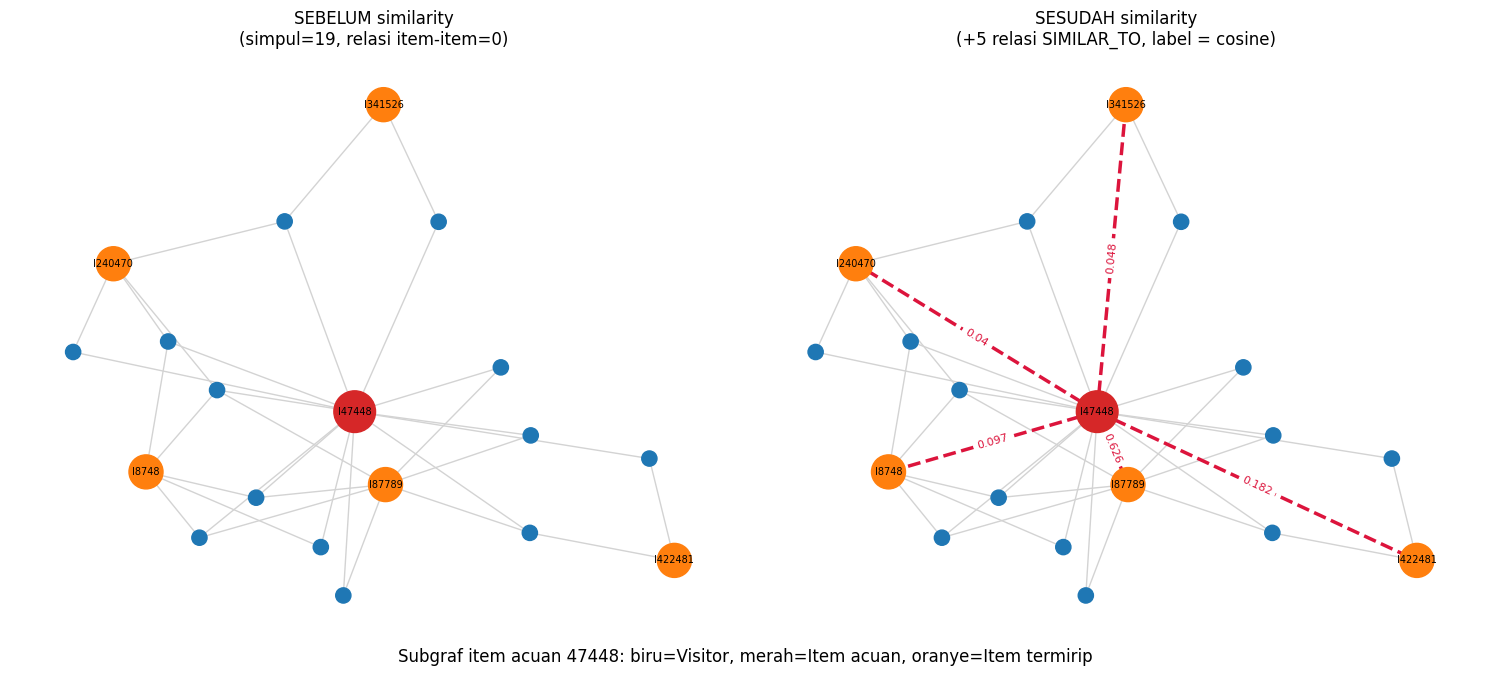


-- SEBELUM (tanpa SIMILAR_TO)
MATCH (v:Visitor)-[r1:VIEWED|ADDED_TO_CART|BOUGHT]->(a:Item {itemId: 47448})
MATCH (v)-[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item) WHERE b.itemId IN [87789, 422481, 8748, 341526, 240470]
RETURN v, r1, a, r2, b

-- SESUDAH (tambah SIMILAR_TO)
MATCH (a:Item {itemId: 47448})-[s:SIMILAR_TO]->(b:Item)
RETURN a, s, b ORDER BY s.score DESC LIMIT 5



In [16]:
URI, AUTH, DATABASE = "neo4j://127.0.0.1:7687", ("neo4j", "password"), "UTS"
try:
    driver.verify_connectivity()
except Exception:
    driver = GraphDatabase.driver(URI, auth=AUTH)
    driver.verify_connectivity()

def run_query(query, **params):
    with driver.session(database=DATABASE) as session:
        return [r.data() for r in session.run(query, **params)]

REF_ITEM = 47448   # item acuan yang sama dengan soal 7

Q_GLOBAL = """
MATCH ()-[r]->()
RETURN type(r) AS relasi,
       count(r) AS sesudah,
       sum(CASE WHEN type(r) = 'SIMILAR_TO' THEN 0 ELSE 1 END) AS sebelum
ORDER BY sesudah DESC
"""
df_global = pd.DataFrame(run_query(Q_GLOBAL))
print(df_global.to_string(index=False))
print("Total sebelum:", df_global["sebelum"].sum(), "| Total sesudah:", df_global["sesudah"].sum())

#Cypher SEBELUM similarity 
Q_SIMS = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN b.itemId AS item ORDER BY s.score DESC LIMIT 5
"""
sims = [r["item"] for r in run_query(Q_SIMS, ref=REF_ITEM)]
print("Item termirip:", sims)

Q_BEFORE = """
MATCH (v:Visitor)-[r1:VIEWED|ADDED_TO_CART|BOUGHT]->(a:Item {itemId: $ref})
MATCH (v)-[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item)
WHERE b.itemId IN $sims
RETURN DISTINCT v.visitorId AS visitor, a.itemId AS item_acuan, b.itemId AS item_lain
"""
rows_before = run_query(Q_BEFORE, ref=REF_ITEM, sims=sims)
df_before = pd.DataFrame(rows_before)
print("SEBELUM:", len(df_before), "pasangan (visitor, item_lain); relasi item-item = 0")
print(df_before.head(10).to_string(index=False))

#Cypher SESUDAH similarity
Q_AFTER = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS dari, b.itemId AS ke, s.score AS similarity, s.common AS user_bersama
ORDER BY s.score DESC LIMIT 5
"""
df_after = pd.DataFrame(run_query(Q_AFTER, ref=REF_ITEM))
print("SESUDAH: relasi SIMILAR_TO yang muncul")
print(df_after.to_string(index=False))

#graf networkx
def build_graph(with_similarity):
    G = nx.Graph()
    G.add_node(f"I{REF_ITEM}", kind="ref")
    for it in sims:
        G.add_node(f"I{it}", kind="sim")
    for _, r in df_before.iterrows():
        G.add_node(f"V{r['visitor']}", kind="visitor")
        G.add_edge(f"V{r['visitor']}", f"I{r['item_acuan']}", rel="interaksi")
        G.add_edge(f"V{r['visitor']}", f"I{r['item_lain']}", rel="interaksi")
    if with_similarity:
        for dari, ke, sim in zip(df_after["dari"], df_after["ke"], df_after["similarity"]):
            G.add_edge(f"I{int(dari)}", f"I{int(ke)}", rel="similar", w=round(float(sim), 3))
    return G

G_before, G_after = build_graph(False), build_graph(True)
pos = nx.spring_layout(G_before, seed=42, k=0.6)   # posisi yang sama untuk kedua plot

def draw(G, ax, judul):
    warna = {"visitor": "tab:blue", "ref": "tab:red", "sim": "tab:orange"}
    ukuran = {"visitor": 120, "ref": 900, "sim": 600}
    nodes = list(G.nodes)
    nx.draw_networkx_nodes(G, pos, nodelist=nodes, ax=ax,
                           node_color=[warna[G.nodes[n]["kind"]] for n in nodes],
                           node_size=[ukuran[G.nodes[n]["kind"]] for n in nodes])
    e_int = [(u, v) for u, v, d in G.edges(data=True) if d["rel"] == "interaksi"]
    e_sim = [(u, v) for u, v, d in G.edges(data=True) if d["rel"] == "similar"]
    nx.draw_networkx_edges(G, pos, edgelist=e_int, ax=ax, edge_color="lightgray", width=1)
    nx.draw_networkx_edges(G, pos, edgelist=e_sim, ax=ax, edge_color="crimson", width=2.5, style="dashed")
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=7,
                            labels={n: n for n in nodes if G.nodes[n]["kind"] != "visitor"})
    nx.draw_networkx_edge_labels(G, pos, ax=ax, font_size=8, font_color="crimson",
                                 edge_labels={(u, v): d["w"] for u, v, d in G.edges(data=True) if d["rel"] == "similar"})
    ax.set_title(judul); ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
draw(G_before, axes[0], f"SEBELUM similarity\n(simpul={G_before.number_of_nodes()}, relasi item-item=0)")
draw(G_after, axes[1], f"SESUDAH similarity\n(+{len(df_after)} relasi SIMILAR_TO, label = cosine)")
fig.suptitle(f"Subgraf item acuan {REF_ITEM}: biru=Visitor, merah=Item acuan, oranye=Item termirip", y=0.02)
plt.tight_layout(); plt.show()

#Query 
print(f"""
-- SEBELUM (tanpa SIMILAR_TO)
MATCH (v:Visitor)-[r1:VIEWED|ADDED_TO_CART|BOUGHT]->(a:Item {{itemId: {REF_ITEM}}})
MATCH (v)-[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item) WHERE b.itemId IN {sims}
RETURN v, r1, a, r2, b

-- SESUDAH (tambah SIMILAR_TO)
MATCH (a:Item {{itemId: {REF_ITEM}}})-[s:SIMILAR_TO]->(b:Item)
RETURN a, s, b ORDER BY s.score DESC LIMIT 5
""")

Sebelum similarity, graf hanya memuat relasi interaksi Visitor → Item (VIEWED, ADDED_TO_CART, BOUGHT) sebanyak 610.393. Item tidak terhubung secara langsung, dan kemiripannya hanya dapat ditelusuri melalui visitor yang berinteraksi dengan keduanya. Pada subgraf item acuan 47448, terdapat 20 pasangan (visitor, item) yang menghubungkannya dengan lima item termirip, tanpa satu pun relasi item-item.

Sesudah similarity, ditambahkan 85.350 relasi SIMILAR_TO (Item → Item) beserta properti score, common, dan method, sehingga total relasi menjadi 695.743 (+13,98%). Relasi interaksi asli tidak berubah. Pada item acuan 47448, kemiripan tersebut kini tampil sebagai lima relasi langsung berskor 0,626 (item 87789) hingga 0,040 (item 240470). Skor tidak semata-mata ditentukan oleh jumlah user bersama, melainkan juga oleh bobot interaksi dan norma vektor tiap item.

# 2.2 Analytics
# 1

In [17]:
SOURCE = r"C:\Users\acer\Documents\latihan\graf\UTS"
URI, AUTH, DATABASE = "neo4j://127.0.0.1:7687", ("neo4j", "GSD12345"), "UTS"

K_NEIGH = 5          # k pada KNN (tetangga per item)
N_AD = 3             # jumlah item yang diiklankan
TOP_N = 5            # panjang ranking untuk evaluasi @5
SEED = 42            # seed proses acak pemilihan user
RELEVANT_EVENTS = ["view", "addtocart", "transaction"]   # event P2 yang dianggap relevan

try:
    driver.verify_connectivity()
except Exception:
    driver = GraphDatabase.driver(URI, auth=AUTH)
    driver.verify_connectivity()

def run_query(query, **params):
    with driver.session(database=DATABASE) as session:
        return [r.data() for r in session.run(query, **params)]

try:
    R, user_ids, item_ids
except NameError:   
    R = sp.load_npz(os.path.join(SOURCE, "R_P1_user_item.npz")).tocsr()
    user_ids = np.load(os.path.join(SOURCE, "user_ids_P1.npy"))
    item_ids = np.load(os.path.join(SOURCE, "item_ids_P1.npy"))

df_sim = pd.read_csv(os.path.join(SOURCE, "similarity_item_topK_P1.csv"))
df_sim = df_sim.sort_values(["itemA", "score", "itemB"], ascending=[True, False, True])

neighbors = {}
for a, b, s in zip(df_sim["itemA"].tolist(), df_sim["itemB"].tolist(), df_sim["score"].tolist()):
    lst = neighbors.setdefault(a, [])
    if len(lst) < K_NEIGH:
        lst.append((b, s))
print("Item dengan tetangga:", len(neighbors))

#Fungsi rekomendasi KNN dan metrik
def recommend(history, neighbors, k=K_NEIGH, topn=TOP_N):
    """history: list[(itemId, bobot)]. Return list[(itemId, skor)] terurut."""
    seen = {i for i, _ in history}
    skor = {}
    for item, w in history:
        for nb, sim in neighbors.get(item, [])[:k]:
            if nb in seen:                     
                continue
            skor[nb] = skor.get(nb, 0.0) + w * sim
    ranked = sorted(skor.items(), key=lambda x: (-x[1], x[0]))   # tie-break deterministik
    return ranked[:topn]

def hit_at_k(ranked_ids, relevant, k):
    return int(any(i in relevant for i in ranked_ids[:k]))

def dcg(rels):
    return sum(r / math.log2(pos + 2) for pos, r in enumerate(rels))

def ndcg_at_k(ranked_ids, relevant, k):
    rels = [1 if i in relevant else 0 for i in ranked_ids[:k]]
    ideal = [1] * min(len(relevant), k)
    return dcg(rels) / dcg(ideal) if ideal else 0.0

#Ground truth dari P2
p2 = pd.read_csv(os.path.join(SOURCE, "events_P2_testing.csv"),
                 usecols=["visitorid", "itemid", "event"])
p2 = p2[p2["event"].isin(RELEVANT_EVENTS)]
p2_items = p2.groupby("visitorid")["itemid"].agg(set)
print("User di P2:", len(p2_items))

def get_history(row_idx):
    s, e = R.indptr[row_idx], R.indptr[row_idx + 1]
    return list(zip(item_ids[R.indices[s:e]].tolist(), R.data[s:e].tolist()))

common_users = np.intersect1d(user_ids, p2_items.index.values)
row_idx = pd.Index(user_ids).get_indexer(common_users)

baris = []
for u, r in zip(common_users.tolist(), row_idx):
    hist = get_history(r)
    seen = {i for i, _ in hist}
    relevant = p2_items[u] - seen
    if not relevant:
        continue
    recs = recommend(hist, neighbors)
    if len(recs) < N_AD:
        continue
    ids = [i for i, _ in recs]
    baris.append({"visitorid": u, "n_riwayat": len(hist), "n_relevan": len(relevant),
                  "hit5": hit_at_k(ids, relevant, TOP_N),
                  "ndcg5": ndcg_at_k(ids, relevant, TOP_N)})
df_eval = pd.DataFrame(baris)

print(f"User di P1 dan P2          : {len(common_users)}")
print(f"User dapat dievaluasi      : {len(df_eval)}")
print(f"Konteks (semua user eval)  : Hit@5 = {df_eval['hit5'].mean():.4f} | "
      f"NDCG@5 = {df_eval['ndcg5'].mean():.4f}")

#Pilih 1 user secara acak 
populasi = np.sort(df_eval["visitorid"].values)
rng = np.random.default_rng(SEED)
USER_PICK = int(rng.choice(populasi))
print("Populasi pengundian:", len(populasi), "| user terpilih:", USER_PICK)

#(1a) Rekomendasi KNN dari graf Neo4j (Cypher)
Q_KNN = """
MATCH (v:Visitor {visitorId: $uid})-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WITH i, sum(CASE type(r)
              WHEN 'VIEWED' THEN 1
              WHEN 'ADDED_TO_CART' THEN 3
              WHEN 'BOUGHT' THEN 5
            END) AS w
CALL {
  WITH i
  MATCH (i)-[s:SIMILAR_TO]->(j:Item)
  RETURN j, s.score AS sim
  ORDER BY sim DESC, j.itemId ASC
  LIMIT $k
}
RETURN i.itemId AS item_user, w, j.itemId AS kandidat, sim
"""
df_knn = pd.DataFrame(run_query(Q_KNN, uid=USER_PICK, k=K_NEIGH))
print("Riwayat & tetangga (k=5) dari graf:")
print(df_knn.to_string(index=False))

hist_graph = list(df_knn.drop_duplicates("item_user")[["item_user", "w"]]
                  .itertuples(index=False, name=None))

Q_HIST = """
MATCH (v:Visitor {visitorId: $uid})-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN i.itemId AS item, sum(CASE type(r) WHEN 'VIEWED' THEN 1
                                           WHEN 'ADDED_TO_CART' THEN 3
                                           WHEN 'BOUGHT' THEN 5 END) AS w
"""
hist = [(int(r["item"]), float(r["w"])) for r in run_query(Q_HIST, uid=USER_PICK)]
print("Riwayat user di P1:", hist)

recs = recommend(hist, neighbors)                       # ranking top-5
konsisten = recs == recommend(get_history(pd.Index(user_ids).get_loc(USER_PICK)), neighbors)
print("Hasil graf konsisten dengan matriks:", konsisten)

#(1b) 3 item yang diiklankan (k=5)
df_rec = pd.DataFrame(recs, columns=["itemId", "skor"])
df_rec.insert(0, "rank", range(1, len(df_rec) + 1))
iklan = df_rec.head(N_AD)
print("\nRanking top-5:"); print(df_rec.to_string(index=False))
print(f"\n{N_AD} item yang diiklankan (k={K_NEIGH}):", iklan["itemId"].tolist())



Item dengan tetangga: 17927
User di P2: 311128


Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (i) { ... }', position=<SummaryInputPosition line=8, column=1, offset=238>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 238, 'line': 8, 'column': 1}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\nMATCH (v:Visitor {visitorId: $uid})-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)\nWITH i, sum(CASE type(r)\n              WHEN 'VIEWED' THEN 1\n              WHEN 'ADDED_TO_CART' THEN 3\n              WHEN 'BOUGHT' THEN 5\n            END) AS w\nCALL {\n  WITH i\n  MATCH (i)-[s:SIMILAR_TO]->(j:Item)\n  RETURN j, s.score AS sim\n  ORDER BY si

User di P1 dan P2          : 7693
User dapat dievaluasi      : 3059
Konteks (semua user eval)  : Hit@5 = 0.0212 | NDCG@5 = 0.0084
Populasi pengundian: 3059 | user terpilih: 120075
Riwayat & tetangga (k=5) dari graf:
 item_user  w  kandidat      sim
    352723  1    344616 0.463679
    352723  1    295537 0.132453
    352723  1    368060 0.106824
    352723  1    158666 0.056680
    352723  1    354709 0.045580
Riwayat user di P1: [(352723, 1.0), (191839, 1.0)]
Hasil graf konsisten dengan matriks: True

Ranking top-5:
 rank  itemId     skor
    1  344616 0.463679
    2  295537 0.132453
    3  368060 0.106824
    4  158666 0.056680
    5  354709 0.045580

3 item yang diiklankan (k=5): [344616, 295537, 368060]


## 1. Cara Kerja Rekomendasi (1A)

Metode yang digunakan adalah KNN Item-Based Collaborative Filtering pada graf `SIMILAR_TO`. Metode ini merekomendasikan item berdasarkan kemiripan dengan item yang pernah berinteraksi dengan pengguna.

### Tahapan Rekomendasi

1. Mengambil riwayat interaksi pengguna pada periode P1 beserta bobotnya, yaitu `VIEWED` = 1, `ADDED_TO_CART` = 3, dan `BOUGHT` = 5.
2. Mencari lima tetangga terdekat (`k = 5`) untuk setiap item dalam riwayat pengguna berdasarkan nilai cosine similarity pada relasi `SIMILAR_TO`.
3. Menghitung skor kandidat dengan menjumlahkan hasil perkalian bobot interaksi dan nilai cosine similarity dari setiap item riwayat yang terhubung dengan kandidat.
4. Menyaring kandidat dengan menghapus item yang sudah pernah dilihat pengguna pada periode P1. Kandidat kemudian diurutkan berdasarkan skor tertinggi. Jika skor sama, pengurutan dilakukan berdasarkan `itemId` agar hasil konsisten.
5. Mengambil lima kandidat teratas untuk evaluasi dan tiga kandidat teratas untuk ditampilkan sebagai iklan rekomendasi.

Hasil perhitungan melalui graf menggunakan Cypher sama dengan hasil perhitungan melalui matriks, dengan nilai `konsisten: True`. Hal ini menunjukkan bahwa kedua implementasi menghasilkan rekomendasi yang konsisten.

## 2. Analisis Pengguna Terpilih (1B)

Pengguna dengan ID 120075 dipilih menggunakan `default_rng(42)` dari populasi 3.059 pengguna yang memenuhi kriteria evaluasi. Penggunaan seed `42` membuat proses pemilihan dapat direproduksi.

### Riwayat Interaksi Pengguna

| Item ID | Jenis Interaksi | Bobot |
| ------- | --------------- | ----- |
| 352723  | `VIEWED`        | 1     |
| 191839  | `VIEWED`        | 1     |

Pengguna memiliki dua item dalam riwayat P1, tetapi hanya item 352723 yang menghasilkan kandidat rekomendasi karena item 191839 tidak memiliki relasi `SIMILAR_TO`.

### Hasil Ranking Rekomendasi

| Peringkat | Item ID | Skor   |
| --------- | ------- | ------ |
| 1         | 344616  | 0,4637 |
| 2         | 295537  | 0,1325 |
| 3         | 368060  | 0,1068 |
| 4         | 158666  | 0,0567 |
| 5         | 354709  | 0,0456 |

Tiga item teratas yang dipilih sebagai rekomendasi iklan adalah 344616, 295537, dan 368060.

### Insight dan Interpretasi

1\. Rekomendasi hanya bersumber dari satu item riwayat. Item 352723 memiliki bobot interaksi sebesar 1 karena hanya dilihat. Oleh karena itu, skor kandidat sama dengan nilai cosine similarity-nya. Tidak ada kontribusi dari item 191839 untuk memperkuat skor kandidat.

2\. Item rekomendasi pertama memiliki skor dominan. Item 344616 memperoleh skor 0,4637, sekitar 3,5 kali skor item peringkat kedua, yaitu 295537 dengan skor 0,1325. Hal ini menunjukkan bahwa item 344616 memiliki kemiripan yang jauh lebih tinggi dibandingkan kandidat berikutnya berdasarkan metode yang digunakan.

3\. Cakupan rekomendasi masih terbatas. Satu dari dua item riwayat pengguna, yaitu 191839, tidak berkontribusi dalam pembentukan kandidat karena tidak memiliki relasi `SIMILAR_TO`. Kondisi ini menggambarkan keterbatasan cakupan graf, ketika hanya sekitar 15,3% item yang memiliki tetangga berdasarkan hasil sebelumnya.

4\. Skor similarity bukan probabilitas pembelian. Skor 0,4637 menunjukkan nilai kemiripan berdasarkan perhitungan model, bukan peluang sebesar 46,37% bahwa pengguna akan membeli item 344616. Hasil rekomendasi perlu dievaluasi lebih lanjut menggunakan data pengujian untuk mengetahui relevansinya.

## 2

In [18]:
seen = {i for i, _ in hist}
relevant = p2_items[USER_PICK] - seen
ranked_ids = df_rec["itemId"].tolist()

print("Item relevan (baru di P2):", sorted(relevant))
df_rec["relevan"] = df_rec["itemId"].isin(relevant).astype(int)
print(df_rec.to_string(index=False))

rels = df_rec["relevan"].tolist()[:TOP_N]
DCG = dcg(rels)
IDCG = dcg([1] * min(len(relevant), TOP_N))
print(f"\nHit@5  = {hit_at_k(ranked_ids, relevant, 5)}")
print(f"DCG@5  = {DCG:.4f} | IDCG@5 = {IDCG:.4f}")
print(f"NDCG@5 = {ndcg_at_k(ranked_ids, relevant, 5):.4f}")
print(f"(pembanding untuk 3 iklan) Hit@3 = {hit_at_k(ranked_ids, relevant, 3)} | "
      f"NDCG@3 = {ndcg_at_k(ranked_ids, relevant, 3):.4f}")

Item relevan (baru di P2): [82575, 368060, 401285]
 rank  itemId     skor  relevan
    1  344616 0.463679        0
    2  295537 0.132453        0
    3  368060 0.106824        1
    4  158666 0.056680        0
    5  354709 0.045580        0

Hit@5  = 1
DCG@5  = 0.5000 | IDCG@5 = 2.1309
NDCG@5 = 0.2346
(pembanding untuk 3 iklan) Hit@3 = 1 | NDCG@3 = 0.2346


Untuk user terpilih (120075), tiga item yang diiklankan dengan k = 5 adalah 344616, 295537, dan 368060. Ground truth berupa item baru yang berinteraksi dengan user tersebut di P2 adalah {82575, 368060, 401285}. Item 368060 muncul di peringkat 3 sehingga Hit@5 = 1. Dengan relevansi biner, DCG@5 = 1/log₂(4) = 0,5000 dan IDCG@5 = 1 + 1/log₂(3) + 1/log₂(4) = 2,1309, sehingga NDCG@5 = 0,2346. Nilai NDCG yang lebih rendah dari Hit mencerminkan bahwa item relevan tidak berada di posisi teratas dan dua item relevan lainnya tidak terambil. Sebagai pembanding, rata-rata pada 3.059 user yang dapat dievaluasi adalah Hit@5 = 0,0212 dan NDCG@5 = 0,0084, sehingga hasil satu user ini tidak mewakili kinerja populasi.